# K-Nearest Neighbors (K-NN): Loss Function and Optimization

## Introduction

The **K-Nearest Neighbors (K-NN)** algorithm is a simple, non-parametric, and instance-based learning method used for classification and regression tasks. Unlike other machine learning algorithms, K-NN does not have an explicit **loss function** or an optimization process during training. Instead, it is a _lazy learning algorithm_, meaning it stores the entire training dataset and defers computation until the prediction phase.

In this lecture, we will describe why K-NN does not use a traditional loss function, discuss how the algorithm works, and explain how certain aspects of K-NN, such as the distance metric and the value of $K$, can be optimized.

## Why K-NN Doesn’t Have a Traditional Loss Function

In K-NN, there is no **training phase** where parameters are optimized to minimize a loss function. The main idea behind K-NN is to store the training data and, when a new query point is presented, the algorithm:

1. Computes the distance between the query point and all training points.
2. Selects the $K$ nearest neighbors based on the distance metric (usually Euclidean distance).
3. For classification, it assigns the majority label of the neighbors. For regression, it takes the average of the neighbors' values.

Since K-NN does not fit a model in the training phase, it does not involve parameter optimization or minimize a loss function explicitly.

## Distance Metric in K-NN

In K-NN, predictions are based on the proximity of data points, which is determined by a distance metric. The most commonly used distance metric is the **Euclidean distance**, defined as:

$$
d(x_i, x_j) = \sqrt{\sum_{k=1}^{n} (x_{ik} - x_{jk})^2}
$$

Other commonly used distance metrics include:

- **Manhattan distance**:

$$
d(x_i, x_j) = \sum_{k=1}^{n} |x_{ik} - x_{jk}|
$$

- **Minkowski distance**:

$$
d(x_i, x_j) = \left( \sum_{k=1}^{n} |x_{ik} - x_{jk}|^p \right)^{\frac{1}{p}}
$$

The choice of the distance metric can significantly affect K-NN’s performance, and it is one of the factors to consider when optimizing K-NN.

## Choosing the Value of $ K $

The number of neighbors $K$ is a crucial hyperparameter in K-NN:

- If $K$ is too small (e.g., $K = 1$), the model can be overly sensitive to noise in the training data, leading to overfitting.
- If $K$ is too large, the model may become too smooth, potentially leading to underfitting.

To choose the optimal value of $K$, one commonly used method is **cross-validation**. By trying different values of \( K \) and evaluating the model’s performance using cross-validation, we can select the value that minimizes the validation error.

## Example: Cross-Validation to Select $K$

The following code demonstrates how to use cross-validation to select the optimal $K$ for K-NN in a classification task:

```python
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
import numpy as np

# Load a sample dataset
iris = load_iris()
X, y = iris.data, iris.target

# Try different values of K and compute the cross-validated accuracy for each
k_values = range(1, 31)
cross_val_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X, y, cv=5, scoring='accuracy')
    cross_val_scores.append(np.mean(scores))

# Find the optimal K
optimal_k = k_values[np.argmax(cross_val_scores)]
print(f"Optimal K: {optimal_k}")

# Plot the cross-validated accuracy as a function of K
import matplotlib.pyplot as plt
plt.plot(k_values, cross_val_scores)
plt.xlabel("K")
plt.ylabel("Cross-validated accuracy")
plt.title("K-NN Cross-Validation to Optimize K")
plt.show()


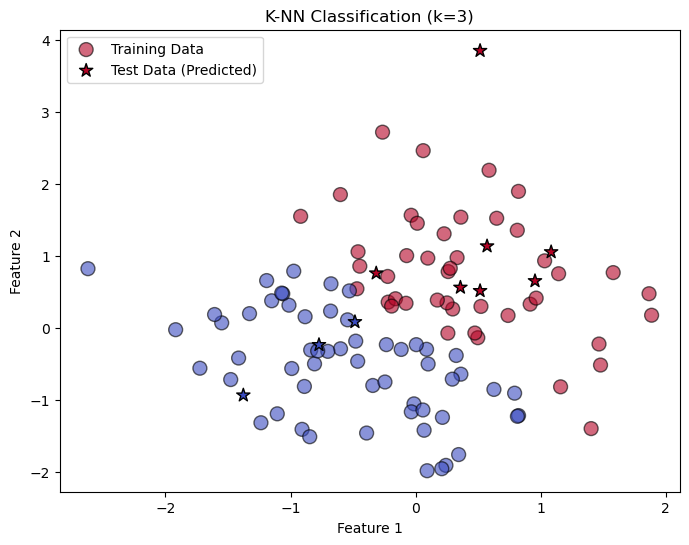

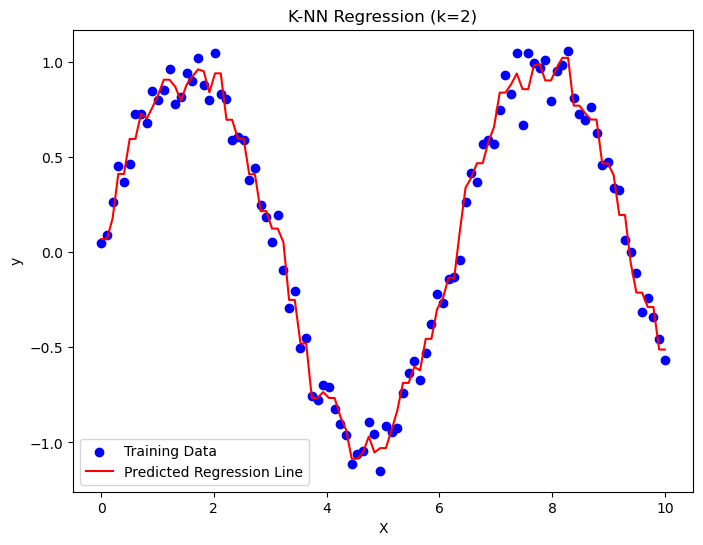

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# Euclidean Distance Function
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))

# K-Nearest Neighbors Classifier
def knn_classification(X_train, y_train, X_test, k=3):
    y_pred = []
    for x_test in X_test:
        # Calculate the distance between x_test and all points in X_train
        distances = [euclidean_distance(x_test, x_train) for x_train in X_train]
        # Get the k-nearest neighbors (sorted by distance)
        k_indices = np.argsort(distances)[:k]
        k_nearest_labels = [y_train[i] for i in k_indices]
        # Majority vote for classification
        most_common = Counter(k_nearest_labels).most_common(1)
        y_pred.append(most_common[0][0])
    return np.array(y_pred)

# K-Nearest Neighbors Regressor
def knn_regression(X_train, y_train, X_test, k=3):
    y_pred = []
    for x_test in X_test:
        # Calculate the distance between x_test and all points in X_train
        distances = [euclidean_distance(x_test, x_train) for x_train in X_train]
        # Get the k-nearest neighbors (sorted by distance)
        k_indices = np.argsort(distances)[:k]
        k_nearest_values = [y_train[i] for i in k_indices]  # have to find the index of K-NN
        # Average the values for regression
        avg_value = np.mean(k_nearest_values)
        y_pred.append(avg_value)
    return np.array(y_pred)

# Generate sample 2D classification data
def generate_classification_data():
    np.random.seed(42)
    X_class = np.random.randn(100, 2)
    y_class = np.array([0 if x[0] + x[1] < 0 else 1 for x in X_class])
    return X_class, y_class

# Generate sample 1D regression data
def generate_regression_data():
    np.random.seed(42)
    X_reg = np.linspace(0, 10, 100).reshape(-1, 1)
    y_reg = np.sin(X_reg).ravel() + np.random.normal(0, 0.1, X_reg.shape[0])
    return X_reg, y_reg

# Plot classification results
def plot_classification(X_train, y_train, X_test, y_pred, title="K-NN Classification"):
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', s=100, alpha=0.6, edgecolors='k', label='Training Data')
    plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred, cmap='coolwarm', s=100, edgecolors='k', marker='*', label='Test Data (Predicted)')
    plt.title(title)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.legend()
    plt.show()

# Plot regression results
def plot_regression(X_train, y_train, X_test, y_pred, title="K-NN Regression"):
    plt.figure(figsize=(8, 6))
    plt.scatter(X_train, y_train, color='blue', label='Training Data')
    plt.plot(X_test, y_pred, color='red', label='Predicted Regression Line')
    plt.title(title)
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend()
    plt.show()

# Test K-NN Classification
X_class, y_class = generate_classification_data()
X_test_class = np.random.randn(10, 2)
y_pred_class = knn_classification(X_class, y_class, X_test_class, k=3)
plot_classification(X_class, y_class, X_test_class, y_pred_class, title="K-NN Classification (k=3)")

# Test K-NN Regression
X_reg, y_reg = generate_regression_data()
X_test_reg = np.linspace(0, 10, 100).reshape(-1, 1)
y_pred_reg = knn_regression(X_reg, y_reg, X_test_reg, k=2)
plot_regression(X_reg, y_reg, X_test_reg, y_pred_reg, title="K-NN Regression (k=2)")
